# 02. Построение проверочного контракта и baseline

**Цель ноутбука.** Преобразовать `raw_data/` в строгую window-level постановку, пригодную для обучения и честной проверки. На этом этапе фиксируются temporal contract, `gap10`, интенсивность приближения к событию, split и baseline-модели.

Ноутбук является методическим центром проекта: именно здесь задается, что модель видит в момент времени, где находится фактический anchor и как исключается утечка через поздние признаки.


In [1]:
from pathlib import Path
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dashboard.final_data_pipeline import PROJECT_ROOT, SEED, artifact_paths, run_pipeline

random.seed(SEED)
np.random.seed(SEED)

RAW_DATA = PROJECT_ROOT / "raw_data"
ARTIFACT_DIR = PROJECT_ROOT / "dashboard" / "artifacts"
PATHS = artifact_paths(ARTIFACT_DIR)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print(f"Источник данных: {RAW_DATA}")
print(f"Каталог артефактов: {ARTIFACT_DIR}")


Источник данных: C:\Main\DGTU\ВКР\Diploma\raw_data
Каталог артефактов: C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts


## 1. Правило формирования окон

Каждое наблюдение — это окно длиной `10` секунд. Для логов дополнительно используется macro-контекст `60` секунд до конца окна. Для failure-run вычисляется `strict_lead_sec`: сколько секунд остается от конца окна до explicit anchor. Окна ближе `10` секунд до события исключаются, чтобы модель не читала сам момент сбоя.

Целевые признаки:

- `y_warning`: окно находится в горизонте до `120` секунд до события;
- `y_risk`: окно находится в горизонте до `30` секунд до события;
- `warning_intensity` и `risk_intensity`: плавная близость к событию внутри соответствующего горизонта.


In [2]:
report = run_pipeline(raw_data=RAW_DATA, artifact_dir=ARTIFACT_DIR)
print(json.dumps(report["written_files"], ensure_ascii=False, indent=2))


{
  "contract": "dashboard\\artifacts\\contract\\strict_intensity_contract.csv.gz",
  "contract_summary": "dashboard\\artifacts\\contract\\strict_contract_summary.csv",
  "baseline_summary": "dashboard\\artifacts\\reports\\baseline_summary_metrics.json",
  "baseline_comparison": "dashboard\\artifacts\\reports\\baseline_comparison_compact.csv",
  "baseline_predictions": "dashboard\\artifacts\\reports\\baseline_predictions.csv.gz",
  "pipeline_report": "dashboard\\artifacts\\reports\\final_data_pipeline_report.json"
}


**Локальный вывод.** После выполнения этой ячейки финальный контур получает единственный канонический вход: `dashboard/artifacts/contract/strict_intensity_contract.csv.gz`. Все downstream-этапы используют именно этот contract.


## 2. Размерность и покрытие contract

Проверяем размер итоговой таблицы, число запусков, распределение по split и покрытие модальностей. Эти величины важны для интерпретации качества: если тестовый split имеет другой профиль покрытия, простое сравнение F1/AP без контекста может быть неверным.


In [3]:
contract = pd.read_csv(PATHS.contract_path, parse_dates=["window_ts", "window_end"], low_memory=False)
contract["window_ts"] = pd.to_datetime(contract["window_ts"], utc=True, errors="coerce")
contract["window_end"] = pd.to_datetime(contract["window_end"], utc=True, errors="coerce")

contract_summary = pd.DataFrame(
    [
        {"Показатель": "Окна", "Значение": len(contract)},
        {"Показатель": "Run", "Значение": contract["run_id"].nunique()},
        {"Показатель": "Workload", "Значение": contract["workload"].nunique()},
        {"Показатель": "Доля warning-окон", "Значение": contract["y_warning"].mean()},
        {"Показатель": "Доля risk-окон", "Значение": contract["y_risk"].mean()},
        {"Показатель": "Доля окон с двумя модальностями", "Значение": contract["has_both_modalities"].mean()},
    ]
)
display(contract_summary)

split_summary = (
    contract.groupby("split")
    .agg(
        окна=("run_id", "size"),
        run=("run_id", "nunique"),
        workload=("workload", "nunique"),
        warning=("y_warning", "mean"),
        risk=("y_risk", "mean"),
        две_модальности=("has_both_modalities", "mean"),
    )
    .reset_index()
)
display(split_summary)


,Показатель,Значение
0,Окна,2378.000000
1,Run,218.000000
2,Workload,16.000000
3,Доля warning-окон,0.309924
4,Доля risk-окон,0.100505
5,Доля окон с двумя модальностями,0.722876


,split,окна,run,workload,warning,risk,две_модальности
0,test,468,51,4,0.185897,0.081197,0.666667
1,train,1407,114,9,0.285004,0.087420,0.653873
2,validation,503,53,3,0.495030,0.155070,0.968191


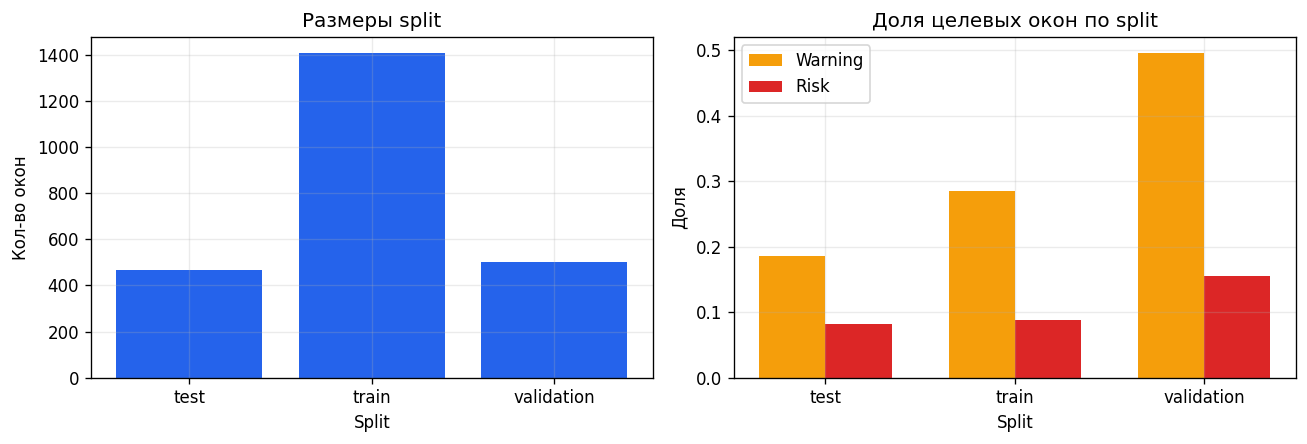

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].bar(split_summary["split"], split_summary["окна"], color="#2563eb")
axes[0].set_title("Размеры split")
axes[0].set_ylabel("Кол-во окон")
axes[0].set_xlabel("Split")

x = np.arange(len(split_summary))
width = 0.35
axes[1].bar(x - width / 2, split_summary["warning"], width, label="Warning", color="#f59e0b")
axes[1].bar(x + width / 2, split_summary["risk"], width, label="Risk", color="#dc2626")
axes[1].set_xticks(x)
axes[1].set_xticklabels(split_summary["split"])
axes[1].set_title("Доля целевых окон по split")
axes[1].set_ylabel("Доля")
axes[1].set_xlabel("Split")
axes[1].legend()

plt.tight_layout()
plt.show()


**Что показано.** Размеры split и prevalence целевых классов.  
**Что наблюдается.** Классы дисбалансны, особенно `risk`. Поэтому accuracy не является содержательной метрикой, а primary-сравнение должно опираться на Average Precision и run-level alert-поведение.  
**Локальный вывод.** Split и prevalence сохраняются в manifest, чтобы дальнейшие метрики не интерпретировались вне контекста.


## 3. Проверка leakage-control

Проверяется, пересекаются ли run/workload между split. Полное отсутствие пересечения workload — более строгий режим, но даже при смешанной стратегии обязательно отсутствие пересечения `run_id`.


In [5]:
split_sets = {
    split: {
        "run": set(part["run_id"].astype(str)),
        "workload": set(part["workload"].astype(str)),
    }
    for split, part in contract.groupby("split")
}

overlap_rows = []
for left in split_sets:
    for right in split_sets:
        if left >= right:
            continue
        overlap_rows.append(
            {
                "Пара split": f"{left} / {right}",
                "Пересечение run_id": len(split_sets[left]["run"] & split_sets[right]["run"]),
                "Пересечение workload": len(split_sets[left]["workload"] & split_sets[right]["workload"]),
            }
        )
display(pd.DataFrame(overlap_rows))


,Пара split,Пересечение run_id,Пересечение workload
0,test / train,0,0
1,test / validation,0,0
2,train / validation,0,0


**Локальный вывод.** Критический leakage-контроль выполняется на уровне `run_id`: одно и то же выполнение не должно одновременно попадать в обучение и проверку. Workload-профиль дополнительно анализируется как slice-риск.


## 4. Геометрия lead time и intensity

Бинарный `risk` слишком жесткий: два окна с lead time `11` и `29` секунд имеют одинаковую метку, хотя первое существенно ближе к событию. Поэтому в финальной модели используется дополнительная intensity-цель: она обучает не только факт попадания в горизонт, но и нарастание близости к событию.


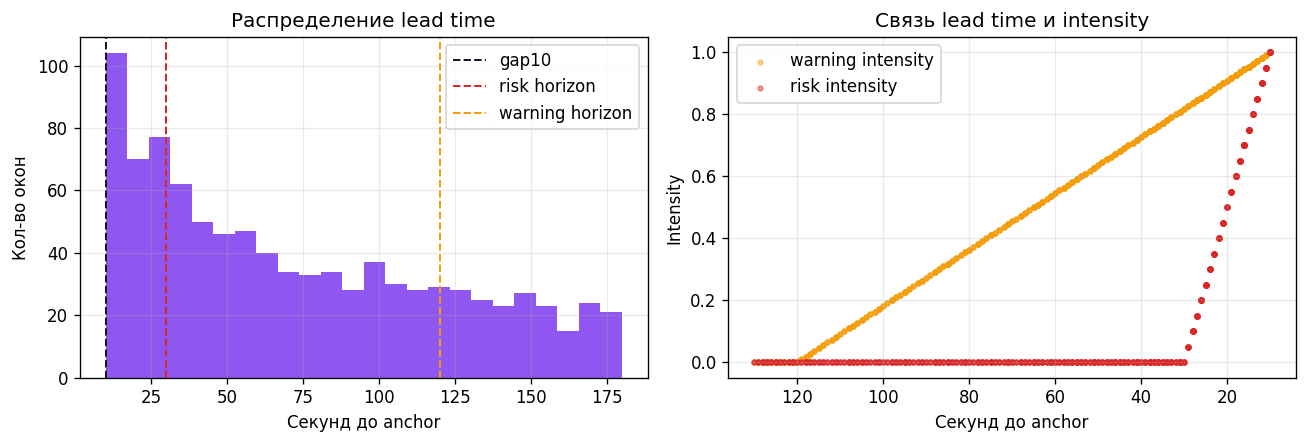

In [6]:
failure_windows = contract.loc[pd.to_numeric(contract["strict_lead_sec"], errors="coerce").notna()].copy()
failure_windows["strict_lead_sec"] = pd.to_numeric(failure_windows["strict_lead_sec"], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
lead_clip = failure_windows.loc[failure_windows["strict_lead_sec"].between(0, 180), "strict_lead_sec"]
axes[0].hist(lead_clip, bins=24, color="#7c3aed", alpha=0.85)
axes[0].axvline(10, color="#111827", linestyle="--", linewidth=1.2, label="gap10")
axes[0].axvline(30, color="#dc2626", linestyle="--", linewidth=1.2, label="risk horizon")
axes[0].axvline(120, color="#f59e0b", linestyle="--", linewidth=1.2, label="warning horizon")
axes[0].set_title("Распределение lead time")
axes[0].set_xlabel("Секунд до anchor")
axes[0].set_ylabel("Кол-во окон")
axes[0].legend()

sample = failure_windows.loc[failure_windows["strict_lead_sec"].between(10, 130)].sort_values("strict_lead_sec")
axes[1].scatter(sample["strict_lead_sec"], sample["warning_intensity"], s=8, alpha=0.45, label="warning intensity", color="#f59e0b")
axes[1].scatter(sample["strict_lead_sec"], sample["risk_intensity"], s=8, alpha=0.45, label="risk intensity", color="#dc2626")
axes[1].invert_xaxis()
axes[1].set_title("Связь lead time и intensity")
axes[1].set_xlabel("Секунд до anchor")
axes[1].set_ylabel("Intensity")
axes[1].legend()

plt.tight_layout()
plt.show()


**Что показано.** Распределение времени до события и плавные intensity-цели.  
**Локальный вывод.** Intensity-постановка лучше соответствует раннему предупреждению: она не заставляет модель воспринимать все положительные окна как одинаковые.


## 5. Покрытие модальностей по workload

Мультимодальная модель должна знать, где доступны обе модальности, а где решение фактически строится на одной. Поэтому в contract сохраняются `log_available`, `kpi_available`, `has_both_modalities` и `kpi_avail_ratio`.


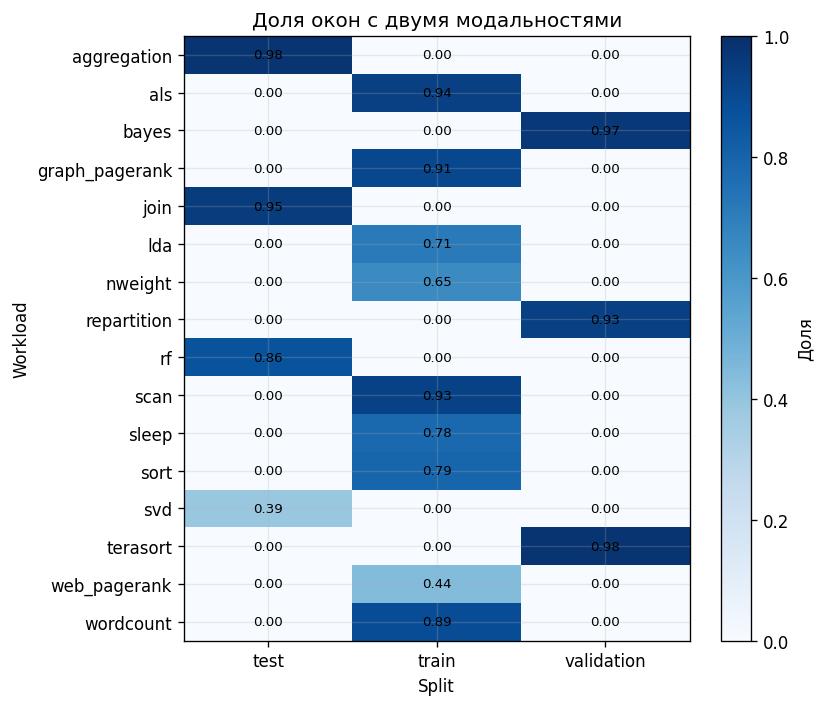

In [7]:
coverage_pivot = (
    contract.pivot_table(index="workload", columns="split", values="has_both_modalities", aggfunc="mean")
    .fillna(0.0)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(coverage_pivot.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(np.arange(len(coverage_pivot.columns)))
ax.set_xticklabels(coverage_pivot.columns)
ax.set_yticks(np.arange(len(coverage_pivot.index)))
ax.set_yticklabels(coverage_pivot.index)
ax.set_title("Доля окон с двумя модальностями")
ax.set_xlabel("Split")
ax.set_ylabel("Workload")
for i in range(coverage_pivot.shape[0]):
    for j in range(coverage_pivot.shape[1]):
        ax.text(j, i, f"{coverage_pivot.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Доля")
plt.tight_layout()
plt.show()


**Локальный вывод.** Покрытие модальностей неодинаково. Поэтому вклад логов и KPI в дашборде должен показываться как диагностика, а не как доказательство причинности.


## 6. Baseline-модели

Baseline используется как нижняя граница и sanity-check. Сравниваются четыре варианта: `log-only`, `kpi-only`, `availability-only` и простой `fused`. Эти модели не являются финальным продуктом, но показывают, где находится сигнал и нет ли очевидной ошибки в contract.


,Цель,Baseline,Average Precision,ROC AUC,Precision,Recall,F1,n,positives,Prevalence
0,y_risk,log-only,0.233249,0.776040,0.106312,0.842105,0.188791,468,38,0.081197
1,y_risk,fused,0.173531,0.654835,0.092105,0.736842,0.163743,468,38,0.081197
2,y_risk,kpi-only,0.166604,0.647674,0.098940,0.736842,0.174455,468,38,0.081197
3,y_risk,availability-only,0.075195,0.334700,0.076577,0.894737,0.141079,468,38,0.081197
4,y_warning,log-only,0.349033,0.672580,0.239544,0.724138,0.360000,468,87,0.185897
5,y_warning,fused,0.336771,0.738740,0.317073,0.298851,0.307692,468,87,0.185897
6,y_warning,kpi-only,0.330834,0.735210,0.344262,0.241379,0.283784,468,87,0.185897
7,y_warning,availability-only,0.177248,0.333303,0.020690,0.034483,0.025862,468,87,0.185897


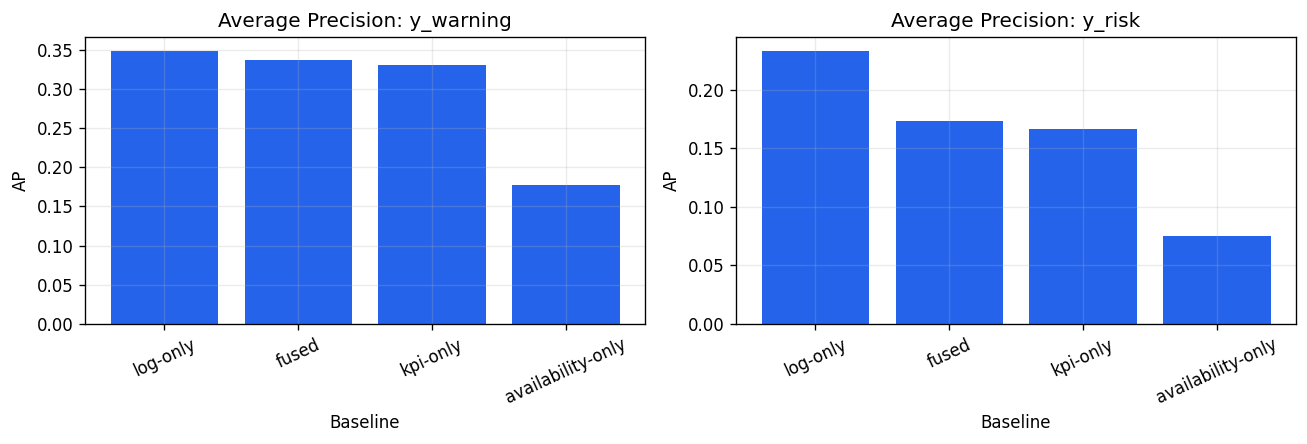

In [8]:
baseline = pd.read_csv(PATHS.baseline_comparison_path)
baseline_display = baseline.sort_values(["target", "average_precision"], ascending=[True, False]).rename(
    columns={
        "target": "Цель",
        "baseline": "Baseline",
        "average_precision": "Average Precision",
        "roc_auc": "ROC AUC",
        "precision": "Precision",
        "recall": "Recall",
        "f1": "F1",
        "prevalence": "Prevalence",
    }
)
display(baseline_display)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for idx, target in enumerate(["y_warning", "y_risk"]):
    part = baseline.loc[baseline["target"].eq(target)].sort_values("average_precision", ascending=False)
    axes[idx].bar(part["baseline"], part["average_precision"], color="#2563eb")
    axes[idx].set_title(f"Average Precision: {target}")
    axes[idx].set_ylabel("AP")
    axes[idx].set_xlabel("Baseline")
    axes[idx].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


In [9]:
pred = pd.read_csv(PATHS.baseline_predictions_path)
top_rows = []
for (target, baseline_name), part in pred.groupby(["target", "baseline"]):
    part = part.sort_values("score", ascending=False).copy()
    top_n = max(1, int(np.ceil(len(part) * 0.10)))
    top = part.head(top_n)
    prevalence = part["label"].mean()
    precision_top10 = top["label"].mean()
    top_rows.append(
        {
            "Цель": target,
            "Baseline": baseline_name,
            "Prevalence": prevalence,
            "Precision@top10%": precision_top10,
            "Lift": precision_top10 / max(prevalence, 1e-9),
        }
    )
top_table = pd.DataFrame(top_rows).sort_values(["Цель", "Lift"], ascending=[True, False])
display(top_table)


,Цель,Baseline,Prevalence,Precision@top10%,Lift
1,y_risk,fused,0.081197,0.234043,2.882419
3,y_risk,log-only,0.081197,0.234043,2.882419
2,y_risk,kpi-only,0.081197,0.212766,2.620381
0,y_risk,availability-only,0.081197,0.000000,0.000000
7,y_warning,log-only,0.185897,0.425532,2.289068
6,y_warning,kpi-only,0.185897,0.319149,1.716801
5,y_warning,fused,0.185897,0.297872,1.602348
4,y_warning,availability-only,0.185897,0.000000,0.000000


**Что показано.** AP и top-10% lift для простых baseline.  
**Что наблюдается.** Baseline позволяет увидеть доминирование логового сигнала и проверить, дает ли KPI дополнительную информацию.  
**Локальный вывод.** Финальная модель должна сравниваться с baseline на том же contract; выигрывать “красивыми кейсами” без глобальной таблицы нельзя.


## 7. Артефакты этапа

Этап `02` передает в модельный ноутбук не произвольный DataFrame, а фиксированные файлы с известным назначением.


In [10]:
artifact_table = pd.DataFrame(
    [
        {"Артефакт": "strict_intensity_contract.csv.gz", "Назначение": "Окна, признаки, цели, split", "Путь": str(PATHS.contract_path.relative_to(PROJECT_ROOT))},
        {"Артефакт": "baseline_predictions.csv.gz", "Назначение": "Прогнозы baseline на test", "Путь": str(PATHS.baseline_predictions_path.relative_to(PROJECT_ROOT))},
        {"Артефакт": "baseline_comparison_compact.csv", "Назначение": "Сводная таблица baseline", "Путь": str(PATHS.baseline_comparison_path.relative_to(PROJECT_ROOT))},
        {"Артефакт": "baseline_summary_metrics.json", "Назначение": "Manifest этапа", "Путь": str(PATHS.baseline_summary_path.relative_to(PROJECT_ROOT))},
    ]
)
display(artifact_table)


,Артефакт,Назначение,Путь
0,strict_intensity_contract.csv.gz,"Окна, признаки, цели, split",dashboard\artifacts\contract\strict_intensity_...
1,baseline_predictions.csv.gz,Прогнозы baseline на test,dashboard\artifacts\reports\baseline_predictio...
2,baseline_comparison_compact.csv,Сводная таблица baseline,dashboard\artifacts\reports\baseline_compariso...
3,baseline_summary_metrics.json,Manifest этапа,dashboard\artifacts\reports\baseline_summary_m...


**Итоговый вывод.** Получена строгая проверочная постановка для мультимодальной модели. Она учитывает временной порядок, дисбаланс, доступность модальностей и baseline. Следующий этап обучает единую fusion-модель и экспортирует replay bundle для дашборда.
